# Тестовое задание: разговорные рекомендации музыки по интенту

Цель — собрать небольшой датасет треков, обогатить его семантическими признаками
(жанр, настроение, контекст, атмосфера и т.д.) и понять, какие из них реально полезны для рекомендаций по текстовому запросу вроде «что-нибудь спокойное для работы».
---

# Задание 1. Сбор датасета

## Источники данных

Основной источник — открытый API Deezer (`api.deezer.com`), ключ для него не нужен.
По каждому треку я беру:

- название, исполнитель, альбом, длительность;
- 30-секундный аудиофрагмент (mp3-превью) и постоянную ссылку на страницу трека;
- популярность (`rank`), дату релиза, BPM, жанр альбома;
- список похожих артистов, его я не использую как признак, только как эталон
  для проверки похожести в задании 5.

Почему не готовый датасет с Kaggle или HuggingFace: мне нужны были одновременно аудио
(для аудио-моделей), известные треки (чтобы LLM что-то о них знала, а результат можно было
проверить на глаз) и внешний эталон похожести. Spotify Tracks с Kaggle — без аудио;
GTZAN, FMA, MTG-Jamendo — с аудио, но с малоизвестными артистами и без эталона похожести.
Минус моего выбора: нет ручных тегов настроения, как в MTG-Jamendo, поэтому настроения
я могу проверить только через согласие разных моделей.

## Как отбирались треки

1. **Ручной список.** Сначала я составил список популярных треков (`seeds.csv`): артист,
   название, жанр, язык. При выборе следил за тем, чтобы:
   - треки покрывали весь диапазон настроений;
   - было несколько треков на границе жанров, чтобы проверить, заметят ли это признаки
2. **Автоматический поиск.** Каждый трек ищется через API, и из найденных вариантов
   выбирается правильная запись по правилам:
   - исполнитель должен совпадать с нужным, иначе это кавер;
   - название трека должно входить в найденное название
     (поиск Deezer иногда совпадает по названию альбома и подставляет другую песню);
   - live, ремиксы, караоке, каверы и т.п. отбрасываются. Radio Edit и Remastered
     оставляю, это тот же трек;
   - из оставшихся берётся самый популярный вариант.
3. **Резерв.** Если оригинальной студийной записи с превью на Deezer нет
   (только ремиксы или live), трек пропускается, а его место занимает
   следующий трек того же жанра из резервного списка.
4. **Классика.** У одного произведения сотни записей, поэтому на Deezer «артист» —
   это исполнитель, а не композитор. Здесь я принимаю записи академических исполнителей
   и оркестров, а аранжировки отбрасываю. Две записи выбрал вручную (`OVERRIDES`).
5. **Проверка.** Две проверки после сбора: «чужой артист» и «не та версия».
   Подробнее в разделе «Контроль качества».

Итог: 80 треков; при последней сборке пропущен 1 трек (Nina Simone — Feeling Good:
на Deezer только ремиксы), вместо него взят резервный (Duke Ellington — Take the A Train);
2 трека классики выбраны вручную.

Важно: доступность каталога Deezer зависит от региона сервера. В первой сборке (23.10)
у Adele, System of a Down, Sia, Kanye West, Metallica, Iron Maiden и Linkin Park
были только ремиксы или live, и они заменялись резервом. При пересборке 25.10 в другой
сессии Colab их оригиналы нашлись. Поэтому собранный датасет зафиксирован
в `data/tracks_meta.jsonl`, и ноутбук по умолчанию берёт его оттуда.

## Жанры и категории

8 жанров по 10 треков:

| Жанр | Примеры | Зачем в датасете |
|---|---|---|
| pop | The Weeknd, Dua Lipa, Zivert | массовый мейнстрим |
| rock | Queen, Arctic Monkeys, Кино | классика и альтернатива, русский рок |
| hiphop | Kendrick Lamar, Eminem, Баста | вокал-речитатив, ритм |
| electronic | Daft Punk, Avicii, Little Big | танцевальная, высокая энергия |
| jazz | Miles Davis, Dave Brubeck, Norah Jones | инструментал и вокал, спокойное настроение |
| classical | Debussy, Чайковский, Рахманинов | без вокала, широкий диапазон энергии |
| metal | Rammstein, Metallica, Ария | максимальная энергия, агрессивное настроение |
| ambient | Brian Eno, Tycho, Nujabes | минимальная энергия, фон для работы и сна |

По языку: 44 англоязычных, 9 русскоязычных, 26 инструментальных, 1 на немецком (Rammstein).
В pop, rock, hiphop и metal есть русскоязычные артисты, в классике — русские композиторы.

## Ограничения на количество

- **Ровно 10 треков на жанр.** Если в одном жанре треков будет в разы больше, он
  перекосит распределения в EDA, а соседи в модели похожести будут в основном из него.
- **Не больше 2 треков на артиста.** Иначе похожесть сведётся к «один и тот же артист»,
  и будет непонятно, ловят ли признаки что-то кроме этого. Фактически в итоговом датасете у каждого артиста ровно 1 трек.

Оба ограничения проверяются в коде (`MAX_PER_GENRE`, `MAX_PER_ARTIST`).



In [93]:
!pip install -q "transformers<5" bitsandbytes

In [94]:
import requests, time, json
import pandas as pd
from pathlib import Path

DATA = Path("data")
AUDIO = DATA / "audio"
AUDIO.mkdir(parents=True, exist_ok=True)

API = "https://api.deezer.com"

In [95]:
# Данные для воспроизведения: seeds.csv и замороженный датасет берём из репозитория.
# Каталог Deezer зависит от региона сервера, поэтому датасет не пересобирается,
# а загружается в том виде, в котором был собран для этой работы.
REPO_RAW = "https://raw.githubusercontent.com/arsennn7/vk_music-semantic-features/main"
for f in ["seeds.csv", "data/tracks_meta.jsonl", "data/llm_raw.json"]:
    p = Path(f)
    if not p.exists():
        p.parent.mkdir(parents=True, exist_ok=True)
        r = requests.get(f"{REPO_RAW}/{f}", timeout=30)
        r.raise_for_status()
        p.write_bytes(r.content)
        print("скачан", f)

In [96]:
def dz_get(path, params=None, retries=5):
    for attempt in range(retries):
        try:
            r = requests.get(f"{API}/{path}", params=params, timeout=20)
            js = r.json()
        except (requests.RequestException, ValueError):
            time.sleep(2 * (attempt + 1))              # сеть/таймаут: каждая следующая пауза длиннее
            continue
        if "error" in js:
            if js["error"].get("code") == 4:           # превышен лимит запросов
                time.sleep(2)
                continue
            return None                                # «нет данных» — это настоящий ответ
        time.sleep(0.12)
        return js
    raise RuntimeError(f"Deezer не отвечает: {path}")

In [97]:
import re, unicodedata

def norm(s):
    # нижний регистр, без диакритики (é -> e) и без пунктуации
    s = unicodedata.normalize("NFKD", s.lower())
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"[^\w\s]", "", s).strip()

BAD_VERSION = re.compile(
    r"\b(live|remix|mix|karaoke|cover|tribute|reprise|acoustic|"
    r"instrumental|version|edit|in the style|originally)\b", re.I)

def version_penalty(title):
    t = re.sub(r"radio edit|remaster\w*", "", title.lower())  # это тот же трек
    return 1 if BAD_VERSION.search(t) else 0

def find_track(artist, title, strict_artist=True):
    res = dz_get("search", {"q": f'artist:"{artist}" track:"{title}"', "limit": 25})
    if not res or not res["data"]:
        res = dz_get("search", {"q": f"{artist} {title}", "limit": 25})
    if not res:
        return None

    cands = [t for t in res["data"] if t.get("preview")]
    exact = [t for t in cands if norm(t["artist"]["name"]) == norm(artist)]
    if strict_artist:
        cands = exact                     # чужой артист = кавер, не берём
    else:
        cands = exact or cands            # классика: исполнитель может быть любым
    if not cands:
        return None

    titled = [t for t in cands if norm(title) in norm(t["title"])]
    pool = titled or cands
    # сначала "чистые" версии, среди них самая популярная
    best = min(pool, key=lambda t: (version_penalty(t["title"]), -t["rank"]))
    if strict_artist and version_penalty(best["title"]):
        return None                       # оригинала нет, только ремиксы/live
    return best

In [98]:
def enrich(t):
    full = dz_get(f"track/{t['id']}") or {}
    album = dz_get(f"album/{t['album']['id']}") or {}
    related = dz_get(f"artist/{t['artist']['id']}/related", {"limit": 10}) or {}
    return {
        "deezer_id": t["id"],
        "dz_artist": t["artist"]["name"],
        "dz_title": t["title"],
        "album": t["album"]["title"],
        "duration": t["duration"],
        "rank": t["rank"],
        "explicit": t["explicit_lyrics"],
        "release_date": full.get("release_date"),
        "bpm_deezer": full.get("bpm"),
        "album_genres": [g["name"] for g in album.get("genres", {}).get("data", [])],
        "related_artists": [a["name"] for a in related.get("data", [])],
        "preview_url": t["preview"],
        "link": t["link"],
    }

In [99]:
# Диагностика: смотрим, какие записи есть на Deezer для проблемных треков
def show_candidates(q, n=10):
    res = dz_get("search", {"q": q, "limit": n})
    if not res or not res.get("data"):
        return pd.DataFrame()
    return pd.DataFrame([{
        "id": t["id"],
        "artist": t["artist"]["name"],
        "title": t["title"],
        "album": t["album"]["title"],
        "rank": t["rank"],
        "has_preview": bool(t.get("preview")),
    } for t in res["data"]])

queries = {
    "Adele (строгий)":   'artist:"Adele" track:"Rolling in the Deep"',
    "Adele (свободный)": "Adele Rolling in the Deep",
    "Tchaikovsky":       "Tchaikovsky Swan Lake orchestra",
    "Shostakovich":      "Shostakovich Waltz No. 2",
    "SOAD (строгий)":    'artist:"System of a Down" track:"Chop Suey"',
    "SOAD (свободный)":  "System of a Down Chop Suey",
}
for name, q in queries.items():
    print(name)
    display(show_candidates(q))

Adele (строгий)


""


Adele (свободный)


,id,artist,title,album,rank,has_preview
0,8086126,Adele,Rolling in the Deep,21,972160,True
1,66539032,Adele,Rolling in the Deep (Jamie xx Shuffle),Rolling in the Deep (Jamie xx Shuffle),509562,True
2,120726068,KO,Adele Medley (Someone Like You / Hello / Set F...,Adele Medley (Someone Like You / Hello / Set F...,118916,True
3,10149031,The Drum & Bass Remixers,Rolling In The Deep (Adele Drum & Bass Re-Mix ...,2010 Pop Hit Drum & Bass Remixes,107924,True
4,69379852,The Piano Man,Rolling in the Deep (Originally Performed By A...,Ultimate Chart Hits On Piano,99976,True
5,840715802,Corey Gray,Rolling In the Deep (Acoustic Tribute to Adele),"Discovery, Vol. 1",89230,True
6,346975901,Hello I'm Adele,Rolling In The Deep,Rolling In The Deep,92691,True
7,12603717,Hitmakers Unlimited,Rolling In The Deep (A Tribute To Adele),2011 Hit List,26630,True
8,10128133,The 808 Remixers,Rolling In The Deep (Adele 808 Re-Mix Party Tr...,2010 Pop Hit 808 Re-Mixes,63973,True
9,63018520,HOT 100,Rolling in the Deep (Originally By Adele Karao...,Rolling in the Deep - (Originally By Adele) [K...,39416,True


Tchaikovsky


...

,id,artist,title,album,rank,has_preview
0,1722900727,Toiro Kuriki,Shostakovich - Waltz No. 2 (The Second Waltz),Eleven Favorite Classical Songs,114936,True
1,2791242272,Penguin Piano,Shostakovich - Waltz No. 2,Rumination,54130,True
2,1791461817,Boris Apostolov,"Shostakovich, Waltz No. 2","Shostakovich, Waltz No. 2",364733,True
3,6944627,Royal Concertgebouw Orchestra,Jazz Suite No. 2 : Shostakovich: Jazz Suite No...,Shostakovich: Orchestral Music & Concertos,470004,True
4,3249058231,Dmitri Shostakovich,Valse No.2,Valse No.2,313463,True
5,2934079371,The Philharmonics,Shostakovich: Waltz aus der Jazz-Suite Nr. 2,Listening to Shostakovich,192295,True
6,4080958771,David Garrett,Suite for Variety Orchestra : Shostakovich: Su...,Immortal,313221,True
7,1061085292,Richard Galliano,Jazz Suite No. 2 - Arr. for Accordion R. Galli...,Valse(s),192352,True
8,116511196,Zantalino and his Orchestra,Waltz No 2 Shostakovich,Ballroom Dancing - The Most Beautiful Ballroom...,204590,True
9,3495820011,Metanio,Dmitri Shostakovich Waltz No. 2,As Romantic as Chopin,214958,True


SOAD (строгий)


""


SOAD (свободный)


,id,artist,title,album,rank,has_preview
0,859699,System of A Down,Chop Suey!,Chop Suey!,940438,True
1,13201895,System of A Down,Chop Suey! (Live Version),The Pledge Of Allegiance Tour Live Concert Rec...,363522,True
2,859702,System of A Down,"War? (Live at Irving Plaza, NYC, NY - January ...",Chop Suey!,338972,True
3,859701,System of A Down,"Sugar (Live at Irving Plaza, NYC, NY - January...",Chop Suey!,195798,True
4,859700,System of A Down,Johnny,Chop Suey!,317565,True
5,61783130,Master of Puppets,Chop Suey,Chop Suey: Tribute to System of a Down,144673,True
6,142040321,Midnite String Quartet,Chop Suey!,MSQ Performs System of a Down,73237,True
7,512183872,8-Bit Misfits,Chop Suey!,8-Bit Versions of System of a Down,48305,True
8,61783139,Master of Puppets,Aerials,Chop Suey: Tribute to System of a Down,72306,True
9,63361047,The Backing Tracks,Chop Suey! (Full Instrumental Performances wit...,"Play Guitar with Linkin Park, Limp Bizkit, Sys...",89945,True


In [100]:
# Ручные исправления: (artist, title) из seeds -> deezer_id правильной записи.
# Классика: на Deezer сотни записей, выбираем академическое исполнение вручную.
OVERRIDES = {
    ("Pyotr Ilyich Tchaikovsky", "Swan Lake"): 3378679,   # André Previn, Act 2 No. 10 Scene (главная тема)
    ("Dmitri Shostakovich", "Waltz No. 2"): 6944627,      # Royal Concertgebouw Orchestra
}

In [101]:
from collections import Counter

MAX_PER_GENRE = 10
MAX_PER_ARTIST = 2
META_PATH = DATA / "tracks_meta.jsonl"

if META_PATH.exists():
    # датасет уже собран — не ходим в Deezer повторно
    df = pd.read_json(META_PATH, lines=True)
    print(f"датасет загружен из кэша: {len(df)} треков")
else:
    seeds = pd.read_csv("seeds.csv")   # сначала основные треки, в конце резерв
    rows, skipped = [], []
    genre_count, artist_count = Counter(), Counter()

    for s in seeds.itertuples(index=False):
        if genre_count[s.seed_genre] >= MAX_PER_GENRE:
            continue                                   # квота жанра уже набрана
        if artist_count[s.artist] >= MAX_PER_ARTIST:
            continue                                   # лимит на артиста
        key = (s.artist, s.title)
        if key in OVERRIDES:
            t = dz_get(f"track/{OVERRIDES[key]}")      # ручная правка
        else:
            t = find_track(s.artist, s.title, strict_artist=(s.seed_genre != "classical"))
        if t is None:
            skipped.append(key)                        # нет оригинала с превью
            continue
        rows.append({**s._asdict(), **enrich(t)})
        genre_count[s.seed_genre] += 1
        artist_count[s.artist] += 1

    df = pd.DataFrame(rows)
    print(f"в датасете: {len(df)} треков")
    print(f"исправлено вручную: {len(OVERRIDES)}")
    print(f"взято из резерва: {df.reserve.sum()}")
    print(f"пропущено (нет оригинала на Deezer): {len(skipped)}")
    for k in skipped:
        print("   ", k)
    print(dict(genre_count))

def download(row):
    path = AUDIO / f"{row.deezer_id}.mp3"
    if not path.exists():
        r = requests.get(row.preview_url, timeout=20)
        if r.status_code != 200 or not r.headers.get("Content-Type", "").startswith("audio"):
            fresh = dz_get(f"track/{row.deezer_id}") or {}   # ссылки подписаны и истекают — берём свежую
            if not fresh.get("preview"):
                raise RuntimeError(f"нет превью для {row.artist} — {row.title} (недоступно в регионе?)")
            r = requests.get(fresh["preview"], timeout=20)
        r.raise_for_status()
        path.write_bytes(r.content)
    return str(path)

df["audio_path"] = [download(r) for r in df.itertuples()]
df.to_json(META_PATH, orient="records", lines=True, force_ascii=False)

датасет загружен из кэша: 80 треков


## Контроль качества

«Найдено 80/80» ещё не значит, что найдено правильно. Поэтому после сбора я сделал
две проверки: исполнитель не совпал с нужным / нашлась не та версия трека.

Без проверки ошибочной оказалась примерно каждая пятая запись.
Диагностические ячейки (`show_candidates`, `clean_options`) я оставил, они показывают, как именно проблемы были найдены.

| Проблема | Пример | Как решил |
|---|---|---|
| Поиск берёт каверы и трибьюты | KO вместо Adele | исполнитель должен совпадать |
| Классика: аранжировки и другие произведения | String Quartet No. 8 вместо Waltz No. 2 | академические записи + ручной выбор |
| Совпадение по альбому, а не по треку | Louis Armstrong → «Hello Brother» | название должно совпадать |
| «Самый популярный» = live или ремикс | Metallica — Enter Sandman (Live) | штраф за версии |
| Нет оригинала в каталоге | Nina Simone — только ремиксы | пропуск + замена из резерва |

In [102]:
mask = (df.dz_artist.str.lower() != df.artist.str.lower())
df.loc[mask, ["artist", "title", "dz_artist", "dz_title"]]

,artist,title,dz_artist,dz_title
54,Pyotr Ilyich Tchaikovsky,Swan Lake,André Previn,"Tchaikovsky: Swan Lake, Op. 20, Act 2: No. 10,..."
55,Sergei Rachmaninoff,Piano Concerto No. 2,Valentina Lisitsa,"Piano Concerto No. 2 in C Minor, Op. 18 : Rach..."
58,Dmitri Shostakovich,Waltz No. 2,Royal Concertgebouw Orchestra,Jazz Suite No. 2 : Shostakovich: Jazz Suite No...


In [103]:
print((df.bpm_deezer == 0).sum(), "треков без BPM")
print((df.album_genres.str.len() == 0).sum(), "треков без жанра альбома")
print((df.related_artists.str.len() == 0).sum(), "треков без похожих артистов")

23 треков без BPM
1 треков без жанра альбома
0 треков без похожих артистов


In [104]:
# Проверка 2: артист правильный, но версия может быть не та (live, ремикс, караоке)
suspicious = r"live|remix|karaoke|cover|instrumental|acoustic|version|edit|mix|remaster"
df.loc[df.dz_title.str.contains(suspicious, case=False),
       ["artist", "title", "dz_title", "album"]]

,artist,title,dz_title,album
12,The Beatles,Come Together,Come Together (Remastered 2009),Abbey Road (Remastered 2009)
31,Avicii,Levels,Levels (Radio Edit),Levels
34,Swedish House Mafia,Don't You Worry Child,Don't You Worry Child (Radio Edit),Don't You Worry Child
45,Frank Sinatra,Fly Me to the Moon,Fly Me To The Moon (2008 Remastered),Nothing But The Best (2008 Remastered)
53,Johann Sebastian Bach,Cello Suite No. 1 Prelude,Suite No. 1 in G Major for Unaccompanied Cello...,"Bach: Cello Suites 1,3 & 5 - Gabrielli: Ricerc..."
59,Metallica,Enter Sandman,Enter Sandman (Remastered 2021),Metallica (Remastered 2021)
60,Iron Maiden,The Trooper,The Trooper (1998 Remaster),Ed Hunter
62,Megadeth,Symphony Of Destruction,Symphony Of Destruction (Remastered 2012),Countdown To Extinction (Deluxe Edition - Rema...
65,Black Sabbath,Paranoid,Paranoid (Remastered 2009),Paranoid
69,Brian Eno,An Ending (Ascent),An Ending (Ascent) (Remastered 2019),Apollo: Atmospheres And Soundtracks (Extended ...


In [105]:
# Диагностика 2: есть ли у проблемных треков оригинал с превью?
def clean_options(artist, title):
    res = dz_get("search", {"q": f"{artist} {title}", "limit": 50})
    rows = []
    for t in (res or {}).get("data", []):
        if norm(t["artist"]["name"]) == norm(artist) and norm(title) in norm(t["title"]):
            rows.append({
                "id": t["id"],
                "title": t["title"],
                "album": t["album"]["title"],
                "rank": t["rank"],
                "preview": bool(t.get("preview")),
                "penalty": version_penalty(t["title"]),
            })
    return pd.DataFrame(rows)

problems = [
    ("Sia", "Chandelier"),
    ("Kanye West", "Stronger"),
    ("Nina Simone", "Feeling Good"),
    ("Metallica", "Enter Sandman"),
    ("Iron Maiden", "The Trooper"),
    ("Linkin Park", "Numb"),
]
for a, ti in problems:
    print(a, "—", ti)
    display(clean_options(a, ti))

Sia — Chandelier


,id,title,album,rank,preview,penalty
0,79587580,Chandelier,1000 Forms Of Fear,937345,True,0
1,99625816,Chandelier (Piano Version),1000 Forms Of Fear (Deluxe Version),734306,True,1
2,99625822,Chandelier (Plastic Plates Remix),1000 Forms Of Fear (Deluxe Version),309935,True,1
3,81071868,Chandelier (Four Tet Remix),Chandelier (Remixes),177654,True,1
4,81071872,Chandelier (Cutmore Club Remix),Chandelier (Remixes),162472,True,1
5,81071874,Chandelier (Hector Fonseca Remix),Chandelier (Remixes),134567,True,1
6,81071878,Chandelier (Dev Hynes Remix),Chandelier (Remixes),116582,True,1
7,81071876,Chandelier (Liam Keegan Remix),Chandelier (Remixes),103424,True,1


Kanye West — Stronger


,id,title,album,rank,preview,penalty
0,1178682,Stronger,Stronger,848755,True,0


Nina Simone — Feeling Good


...

,id,title,album,rank,preview,penalty
0,1483825212,Enter Sandman (Remastered 2021),Metallica (Remastered 2021),927758,True,0
1,2114676,Enter Sandman (Live),S&M,422693,True,1
2,69748050,Enter Sandman (Live In Mexico City),Live Sh*t: Binge & Purge (Live In Mexico City),380099,True,1
3,1405866702,"Enter Sandman (Live at Tushino Airfield, Mosco...","Enter Sandman (Live at Tushino Airfield, Mosco...",423844,True,1
4,417678432,"Enter Sandman (Live At House Of Vans, London)","Live At House Of Vans, London, 18.11.16",343387,True,1
5,1059202212,Enter Sandman (Live),S&M2,292703,True,1
6,70697386,Enter Sandman (Live),Metallica Through The Never (Music From The Mo...,228317,True,1
7,624016432,"Enter Sandman (Live At The Masonic, San Franci...",Helping Hands…Live & Acoustic At The Masonic,256839,True,1
8,1489945292,Enter Sandman (Radio Edit),Metallica (Remastered Deluxe Box Set),206560,True,0
9,1489944512,"Enter Sandman (Live at Wembley Stadium, London...",Metallica (Remastered Deluxe Box Set),197849,True,1


Iron Maiden — The Trooper


,id,title,album,rank,preview,penalty
0,3155089,The Trooper (1998 Remaster),Ed Hunter,784417,True,0
1,3155410,The Trooper (Live '01),Rock in Rio (Live),413355,True,1
2,1145040432,"The Trooper (Live in Mexico City, Palacio de l...","Nights of the Dead, Legacy of the Beast: Live ...",382523,True,1
3,3154976,The Trooper (Live at Long Beach Arena; 1998 Re...,Live After Death (1998 Remaster),314499,True,1
4,3166039,The Trooper (Live in Tokyo 16 February 2008),Flight 666: The Original Soundtrack,299455,True,1
5,424915772,The Trooper (Live at Estadio Jorge Magico Gonz...,The Book of Souls: Live Chapter,287153,True,1
6,16929097,"The Trooper (Live At Estadio Nacional, Santiago)",En Vivo!,291858,True,1
7,3120913,The Trooper (Live 2003),Death on the Road,211713,True,1
8,3155031,The Trooper (Live at Donington; 1998 Remaster),Live at Donington (1998 Remaster),129742,True,1
9,3154992,The Trooper (Live; 1998 Remastered Version),A Real Live Dead One (Live; 1998 Remaster),245352,True,1


Linkin Park — Numb


,id,title,album,rank,preview,penalty
0,677232,Numb,Meteora (Bonus Edition),974827,True,0
1,4175528222,Numb - Unshatter Film Soundtrack (Live in São ...,Unshatter Film Soundtrack (Live in São Paulo),668260,True,1
2,676930,Numb (Live),Live in Texas,510166,True,1
3,439281722,Numb (One More Light Live),One More Light Live,387478,True,1
4,50345631,"Numb (Live in New York, 2008)",Meteora Live Around the World,265881,True,1
5,2607923,Numb (Live),Road to Revolution (Live at Milton Keynes),261039,True,1


In [106]:
# Сводка по итоговому датасету
print(pd.crosstab(df.seed_genre, df.lang, margins=True), "\n")
print("максимум треков у одного артиста:", df.artist.value_counts().max(), "\n")
print("взяты из резерва:")
print(df.loc[df.reserve == 1, ["artist", "title", "seed_genre"]].to_string(index=False))

lang        de  en  instr  ru  All
seed_genre                        
ambient      0   1      9   0   10
classical    0   0     10   0   10
electronic   0   8      2   0   10
hiphop       0   7      0   3   10
jazz         0   5      5   0   10
metal        1   8      0   1   10
pop          0   8      0   2   10
rock         0   7      0   3   10
All          1  44     26   9   80 

максимум треков у одного артиста: 1 

взяты из резерва:
        artist            title seed_genre
Duke Ellington Take the A Train       jazz


## Ограничения датасета

- Датасет зависит от того, что доступно на Deezer в регионе, где работает Colab:
  у части известных артистов есть только ремиксы и live, поэтому они не вошли.
- Выборка маленькая - 80 треков.
- 30-секундный фрагмент — не весь трек. Для классики и ambient он может плохо
  передавать произведение целиком.
- Метаданные Deezer неполные: у 23 треков BPM равен 0, а `release_date` — это дата
  конкретного релиза (например, ремастера), а не год выхода песни.
  Поэтому темп считаю сам, а эпоху беру из LLM.
- Ссылки на превью со временем перестают работать, поэтому дополнительно храню
  постоянную ссылку на трек (`link`). Сами mp3 в репозиторий не кладу:
  они защищены авторским правом, и ноутбук скачивает их заново.

# Задание 2. Формирование набора признаков

Метаданные описывают трек как объект каталога (артист, альбом, длительность),
а пользователь формулирует запрос через ощущения и ситуацию: «спокойное, чтобы уснуть».
Общих слов у запроса и метаданных нет. Семантические признаки описывают трек так,
как о нём говорит человек, и связывают запрос с треком.

Каждый признак я отбирал по трём критериям:
1. есть реальный тип запроса, который этот признак закрывает;
2. его можно получить автоматически, без ручной разметки;
3. его можно проверить: сравнить два источника или сверить с эталоном.

## Настроение: энергия × валентность

Настроения я опираю на модель Рассела: эмоцию можно разложить на две оси,
энергию (от спокойного к интенсивному) и валентность (от грустного к радостному).
Обе оси храню числами. Словесные теги настроения — это области на той же плоскости
(calm — низкая энергия и положительная валентность, aggressive — высокая энергия и
отрицательная), поэтому их согласованность с числами можно проверить.

## Признаки

| Признак | Тип | Источник | Пример запроса |
|---|---|---|---|
| Жанр / поджанр | категория | LLM | «включи джаз» |
| Настроение | мультиметка | CLAP + LLM | «что-нибудь грустное» |
| Энергия | 0–1 | librosa + LLM | «бодрое для тренировки» |
| Валентность | 0–1 | LLM | «весёлое» |
| Темп | BPM | librosa | «под бег» |
| Контекст | мультиметка | CLAP + LLM | «для работы», «для вечеринки» |
| Атмосфера | мультиметка | CLAP + LLM | «как саундтрек к ночной поездке» |
| Вокал / инструментал | бинарный | CLAP | «только инструментальное» |
| Эпоха | десятилетие | LLM | «поновее», «из 80-х» |
| Язык | категория | seed | «русское» |
| Похожие артисты | список | LLM | «похожее на Shaman» |

Плюс два эмбеддинга для модели похожести в задании 5: CLAP-эмбеддинг аудио
(как трек звучит) и эмбеддинг текстового описания от LLM (что о треке известно).

## Почему три источника

- **librosa** считает объективные числа по сигналу, но не понимает «грустно» или «для тренировки».
- **CLAP** слушает звук и сравнивает его с текстом, но не знает год выхода и похожих артистов.
- **LLM** знает культурный контекст (эпоха, поджанр, похожие артисты), но звук не слышит
  и может выдумать про трек, который плохо знает.

Настроение и контекст размечают и CLAP, и LLM: где они согласны, признаку можно доверять,
а где нет — это материал для анализа ошибок.

## Решения

- **Закрытый словарь** для настроения, контекста и атмосферы: CLAP и LLM выбирают
  из одного списка, поэтому их ответы можно сравнить, а в EDA синонимы
  («chill», «relaxing», «calm») не размазываются по разным столбцам.
- **Мультиметки**: трек может быть одновременно sad и calm.
- **Небольшой словарь** (7–8 значений): на 80 треках длинный список дал бы много
  значений с 1–2 треками.
- **Словарь на английском**: CLAP обучен на английских подписях.
- **Эпоха от LLM**, а не из Deezer: `release_date` бывает датой ремастера.
- **Похожие артисты от Deezer не входят в признаки**: это эталон для оценки
  в задании 5, иначе оценка будет круговой.

In [107]:
# Закрытый словарь значений: один и тот же для CLAP и LLM,
# чтобы их предсказания можно было напрямую сравнить
VOCAB = {
    "mood": ["energetic", "calm", "happy", "sad",
             "aggressive", "romantic", "dark", "dreamy"],
    "context": ["workout", "party", "focus", "relaxation",
                "sleep", "driving", "romance"],
    "atmosphere": ["night", "summer", "cinematic", "nostalgic",
                   "urban", "cozy", "epic"],
    "vocals": ["vocal", "instrumental"],
}

for k, v in VOCAB.items():
    print(f"{k:12s} ({len(v)}): {', '.join(v)}")

mood         (8): energetic, calm, happy, sad, aggressive, romantic, dark, dreamy
context      (7): workout, party, focus, relaxation, sleep, driving, romance
atmosphere   (7): night, summer, cinematic, nostalgic, urban, cozy, epic
vocals       (2): vocal, instrumental


# Задание 3. Извлечение признаков

In [108]:
import librosa, numpy as np
from tqdm.auto import tqdm

def audio_features(path, sr=22050):
    y, sr = librosa.load(path, sr=sr, mono=True)
    tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
    onset_env = librosa.onset.onset_strength(y=y, sr=sr)
    return {
        "tempo": float(np.atleast_1d(tempo)[0]),
        "rms": float(librosa.feature.rms(y=y).mean()),
        "onset_strength": float(onset_env.mean()),
        "centroid": float(librosa.feature.spectral_centroid(y=y, sr=sr).mean()),
    }

F = pd.DataFrame([audio_features(p) for p in tqdm(df.audio_path)], index=df.index)
df[F.columns] = F

# громкость + ритмичность + тембр (яркость), каждая составляющая в ранге 0..1
df["energy_audio"] = (df.rms.rank(pct=True) + df.onset_strength.rank(pct=True) + df.centroid.rank(pct=True)) / 3

  0%|          | 0/80 [00:00<?, ?it/s]

In [109]:
df.groupby("seed_genre")[["tempo", "energy_audio", "centroid"]].mean().round(2) \
  .sort_values("energy_audio")

,tempo,energy_audio,centroid
seed_genre,,,
classical,131.23,0.16,1083.52
ambient,99.76,0.32,1083.93
jazz,121.62,0.38,2168.05
rock,126.88,0.57,2349.08
metal,132.42,0.59,2565.18
hiphop,124.54,0.63,2248.86
pop,109.87,0.69,2320.22
electronic,113.77,0.71,2850.10


In [110]:
m = df.bpm_deezer > 0
ratio = df.loc[m, "tempo"] / df.loc[m, "bpm_deezer"]
print("треков с BPM от Deezer:", m.sum())
print("совпадает (±5%):", round(((ratio > 0.95) & (ratio < 1.05)).mean(), 2))
print("ошибка ровно в 2 раза:", round((((ratio > 1.9) & (ratio < 2.1)) |
                                         ((ratio > 0.47) & (ratio < 0.53))).mean(), 2))

треков с BPM от Deezer: 57
совпадает (±5%): 0.58
ошибка ровно в 2 раза: 0.16


In [111]:
import torch
from transformers import ClapModel, ClapProcessor

device = "cuda"
CLAP_NAME = "laion/larger_clap_general"   # music-версия выдаёт вырожденные эмбеддинги, см. сравнение ниже
clap = ClapModel.from_pretrained(CLAP_NAME).to(device).eval()
proc = ClapProcessor.from_pretrained(CLAP_NAME)
CLAP_SR = proc.feature_extractor.sampling_rate      # CLAP ждёт 48 kHz

@torch.no_grad()
def clap_embed(chunks=None, texts=None):
    # Полный проход через модель: она сама делает проекции и нормализацию,
    # поэтому аудио и текст точно оказываются в одном пространстве.
    # Модели нужны оба входа сразу, поэтому недостающий подменяем заглушкой.
    if chunks is None:
        chunks = [np.zeros(CLAP_SR * 10, dtype=np.float32)]
    if texts is None:
        texts = ["music"]
    a = proc.feature_extractor(chunks, sampling_rate=CLAP_SR, return_tensors="pt")
    t = proc.tokenizer(texts, padding=True, return_tensors="pt")
    out = clap(**{k: v.to(device) for k, v in {**a, **t}.items()})
    return out.audio_embeds.cpu().numpy(), out.text_embeds.cpu().numpy()

def clap_audio_emb(path, chunk_sec=10):
    y, _ = librosa.load(path, sr=CLAP_SR, mono=True)
    n = chunk_sec * CLAP_SR
    chunks = [y[i:i+n] for i in range(0, len(y), n) if len(y[i:i+n]) >= n // 2]
    e = clap_embed(chunks=chunks)[0].mean(0)        # среднее по 10-секундным кускам
    return e / np.linalg.norm(e)

def clap_text_emb(texts):
    return clap_embed(texts=texts)[1]

A = np.stack([clap_audio_emb(p) for p in tqdm(df.audio_path)])
np.save(DATA / "clap_audio.npy", A)
print(A.shape)

  0%|          | 0/80 [00:00<?, ?it/s]

(80, 512)


In [112]:
import transformers
print("transformers", transformers.__version__)

_, info = ClapModel.from_pretrained(CLAP_NAME, output_loading_info=True)
print("не загружено весов:", len(info["missing_keys"]))
print(info["missing_keys"][:8])
print("лишних весов в файле:", len(info["unexpected_keys"]))
print(info["unexpected_keys"][:8])

transformers 4.57.6
не загружено весов: 0
[]
лишних весов в файле: 0
[]


In [113]:
# Текстовое описание для каждого значения словаря.
# Одно слово ("calm") CLAP понимает хуже, чем фразу, похожую на подписи из его обучения.
PROMPTS = {
    "mood": {
        "energetic": "energetic, upbeat music",
        "calm": "calm, peaceful music",
        "happy": "happy, joyful music",
        "sad": "sad, melancholic music",
        "aggressive": "aggressive, intense music",
        "romantic": "romantic, tender music",
        "dark": "dark, gloomy music",
        "dreamy": "dreamy, ethereal music",
    },
    "context": {
        "workout": "music for a workout at the gym",
        "party": "music for a dance party",
        "focus": "background music for focus and studying",
        "relaxation": "relaxing music to unwind",
        "sleep": "soft music for falling asleep",
        "driving": "music for a long drive",
        "romance": "music for a romantic dinner",
    },
    "atmosphere": {
        "night": "music with a night-time atmosphere",
        "summer": "sunny summer music",
        "cinematic": "cinematic film soundtrack music",
        "nostalgic": "nostalgic retro music",
        "urban": "urban city street music",
        "cozy": "warm, cozy music",
        "epic": "epic, grandiose music",
    },
    "vocals": {
        "vocal": "a song with a singer's vocals",
        "instrumental": "instrumental music without vocals",
    },
}
# защита от опечаток: ключи должны совпадать со словарём из З2
assert all(list(PROMPTS[c]) == VOCAB[c] for c in VOCAB)

In [114]:

scale = clap.logit_scale_a.exp().item()   # «температура», которую модель выучила при обучении

for cat, prompts in PROMPTS.items():
    labels = list(prompts)
    T = clap_text_emb(list(prompts.values()))           # (k, 512)
    sims = A @ T.T                                       # (80, k) косинусные сходства
    z = (sims - sims.mean(0)) / sims.std(0)           # убираем смещение описаний (для всех категорий)
    probs = torch.softmax(torch.tensor(z), dim=1).numpy()
    for j, lab in enumerate(labels):
        df[f"clap_{cat}_{lab}"] = probs[:, j]            # мягкие оценки — пригодятся в EDA
    k = 1 if cat == "vocals" else 2                      # 2 тега на категорию, вокал — один
    top = probs.argsort(1)[:, ::-1][:, :k]
    df[f"clap_{cat}"] = [[labels[i] for i in row] for row in top]

In [115]:
# у нас есть эталон: в seeds язык "instr" = инструментальный трек
pred = df.clap_vocals.str[0] == "instrumental"          # теги после центрирования
true = df.lang == "instr"
sv = A @ clap_text_emb(list(PROMPTS["vocals"].values())).T
print("без центрирования:", round(((sv.argmax(1) == 1) == true).mean(), 2))
print("с центрированием (используем):", round((pred == true).mean(), 2))
pd.crosstab(true.rename("на самом деле instr"), pred.rename("CLAP: instr"))

без центрирования: 0.79
с центрированием (используем): 0.79


CLAP: instr,False,True
на самом деле instr,,
False,38,16
True,1,25


In [116]:
display(pd.crosstab(df.seed_genre, df.clap_mood.str[0]))
df[["artist", "title", "clap_mood", "clap_context", "clap_atmosphere"]].sample(12, random_state=0)

clap_mood,aggressive,calm,dark,dreamy,energetic,happy,romantic,sad
seed_genre,,,,,,,,
ambient,0,3,2,1,0,0,4,0
classical,0,1,0,0,4,0,4,1
electronic,1,0,3,0,3,3,0,0
hiphop,4,1,2,0,1,1,0,1
jazz,0,0,0,1,0,6,2,1
metal,9,0,0,0,0,1,0,0
pop,0,0,2,3,0,5,0,0
rock,3,0,0,0,2,4,0,1


,artist,title,clap_mood,clap_context,clap_atmosphere
50,Claude Debussy,Clair de Lune,"[sad, energetic]","[driving, focus]","[summer, nostalgic]"
27,Баста,Сансара,"[sad, happy]","[driving, romance]","[nostalgic, summer]"
30,Daft Punk,One More Time,"[happy, calm]","[party, workout]","[night, summer]"
77,Moby,Porcelain,"[dreamy, sad]","[driving, sleep]","[cozy, nostalgic]"
45,Frank Sinatra,Fly Me to the Moon,"[happy, dreamy]","[sleep, romance]","[summer, cozy]"
71,Tycho,Awake,"[dark, calm]","[workout, driving]","[urban, night]"
66,Sabaton,Primo Victoria,"[aggressive, energetic]","[workout, party]","[night, epic]"
68,Ария,Беспечный ангел,"[happy, sad]","[romance, driving]","[nostalgic, summer]"
48,Norah Jones,Don't Know Why,"[happy, dreamy]","[sleep, romance]","[summer, cozy]"
69,Brian Eno,An Ending (Ascent),"[romantic, calm]","[relaxation, focus]","[cinematic, cozy]"


In [117]:
# 1) Не слиплись ли аудио-векторы?
S = A @ A.T
off = S[~np.eye(len(A), dtype=bool)]
print(f"сходство разных треков: среднее {off.mean():.3f}, мин {off.min():.3f}, макс {off.max():.3f}")

# 2) Жанр zero-shot — для него есть эталон (seed_genre)
GENRE_PROMPTS = {
    "pop": "pop music", "rock": "rock music", "hiphop": "hip hop rap music",
    "electronic": "electronic dance music", "jazz": "jazz music",
    "classical": "classical orchestral music", "metal": "heavy metal music",
    "ambient": "ambient music",
}
G = clap_text_emb(list(GENRE_PROMPTS.values()))
pred_g = np.array(list(GENRE_PROMPTS))[(A @ G.T).argmax(1)]
print("\nточность жанра zero-shot:", round((pred_g == df.seed_genre).mean(), 2))
print("распределение предсказаний:", pd.Series(pred_g).value_counts().to_dict())

# 3) Смещение описаний: насколько каждое описание близко ко всем трекам в среднем
print()
for cat, prompts in PROMPTS.items():
    sims = A @ clap_text_emb(list(prompts.values())).T
    print(cat, dict(zip(prompts, sims.mean(0).round(3))))

сходство разных треков: среднее 0.449, мин 0.006, макс 0.924

точность жанра zero-shot: 0.69
распределение предсказаний: {'pop': 20, 'rock': 14, 'ambient': 11, 'jazz': 10, 'classical': 10, 'hiphop': 7, 'electronic': 4, 'metal': 4}

mood {'energetic': np.float32(0.118), 'calm': np.float32(0.114), 'happy': np.float32(0.133), 'sad': np.float32(0.168), 'aggressive': np.float32(0.109), 'romantic': np.float32(0.109), 'dark': np.float32(0.171), 'dreamy': np.float32(0.14)}
context {'workout': np.float32(0.085), 'party': np.float32(0.192), 'focus': np.float32(0.152), 'relaxation': np.float32(0.079), 'sleep': np.float32(0.17), 'driving': np.float32(0.139), 'romance': np.float32(0.19)}
atmosphere {'night': np.float32(0.064), 'summer': np.float32(0.128), 'cinematic': np.float32(0.089), 'nostalgic': np.float32(0.17), 'urban': np.float32(0.137), 'cozy': np.float32(0.18), 'epic': np.float32(0.113)}
vocals {'vocal': np.float32(0.082), 'instrumental': np.float32(0.095)}


### Выбор чекпоинта CLAP

Сначала взял `laion/larger_clap_music`, раз она обучена на музыке. Но на ней все треки
получили почти одинаковые векторы (среднее сходство 0,93), а zero-shot жанр предсказывался
как rock для всех 80 треков (точность 0,12 — уровень случайного угадывания).
Проверил, что дело не в версии `transformers` (на 4.57 и 5.20 результат одинаковый)
и не в аудио, а потом сравнил три чекпоинта по zero-shot классификации жанра:
это единственный признак, для которого у меня есть эталон (`seed_genre`).

| Чекпоинт | Точность жанра | Сходство разных треков |
|---|---|---|
| clap-htsat-unfused | 0,44 | 0,585 |
| larger_clap_general | 0,66 | 0,391 |
| larger_clap_music | 0,12 | 0,933 |

Выбрал `larger_clap_general`. Вывод: модель нельзя брать по названию, её надо проверять
на задаче с известным ответом.

In [118]:
# Проверка аудио на входе: длительность и громкость одного файла
y, _ = librosa.load(df.audio_path.iloc[0], sr=48000, mono=True)
print(f"аудио: {len(y)/48000:.1f} c, макс. амплитуда {abs(y).max():.2f}\n")

GENRES = list(GENRE_PROMPTS)

def check_checkpoint(name):
    m = ClapModel.from_pretrained(name).to(device).eval()
    p = ClapProcessor.from_pretrained(name)
    sr = p.feature_extractor.sampling_rate
    with torch.no_grad():
        t = p.tokenizer(list(GENRE_PROMPTS.values()), padding=True, return_tensors="pt").to(device)
        T = torch.nn.functional.normalize(m.get_text_features(**t), dim=-1)
        embs = []
        for path in df.audio_path:
            y, _ = librosa.load(path, sr=sr, mono=True, duration=10)   # первые 10 с — для теста хватит
            a = p.feature_extractor([y], sampling_rate=sr, return_tensors="pt").to(device)
            embs.append(torch.nn.functional.normalize(m.get_audio_features(**a), dim=-1))
        Aa = torch.cat(embs)
    pred = np.array(GENRES)[(Aa @ T.T).argmax(1).cpu().numpy()]
    S = (Aa @ Aa.T).cpu().numpy()
    off = S[~np.eye(len(S), dtype=bool)].mean()
    print(f"{name}\n  точность жанра: {(pred == df.seed_genre.values).mean():.2f}"
          f" | сходство разных треков: {off:.3f}"
          f"\n  предсказания: {pd.Series(pred).value_counts().to_dict()}\n")
    del m; torch.cuda.empty_cache()                  # освобождаем память GPU перед следующей моделью

for name in ["laion/clap-htsat-unfused", "laion/larger_clap_general", "laion/larger_clap_music"]:
    check_checkpoint(name)

аудио: 30.0 c, макс. амплитуда 1.03

laion/clap-htsat-unfused
  точность жанра: 0.44 | сходство разных треков: 0.585
  предсказания: {'pop': 26, 'hiphop': 24, 'metal': 12, 'classical': 9, 'jazz': 5, 'electronic': 2, 'rock': 2}

laion/larger_clap_general
  точность жанра: 0.66 | сходство разных треков: 0.391
  предсказания: {'pop': 21, 'rock': 14, 'jazz': 10, 'ambient': 10, 'hiphop': 9, 'classical': 8, 'electronic': 5, 'metal': 3}

laion/larger_clap_music
  точность жанра: 0.12 | сходство разных треков: 0.933
  предсказания: {'rock': 80}



In [119]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

RAW_PATH = DATA / "llm_raw.json"
ids = [int(i) for i in df.deezer_id]
cache = json.load(open(RAW_PATH)) if RAW_PATH.exists() else {}
NEED_LLM = not (isinstance(cache, dict) and cache.get("ids") == ids)   # кэш есть и от этого же набора треков?

LLM_NAME = "Qwen/Qwen2.5-7B-Instruct"
if NEED_LLM:
    tok = AutoTokenizer.from_pretrained(LLM_NAME, padding_side="left")
    llm = AutoModelForCausalLM.from_pretrained(
        LLM_NAME,
        device_map="auto",
        quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16),
    )
else:
    print("ответы LLM есть в кэше для этого набора треков — модель не загружаем")

ответы LLM есть в кэше для этого набора треков — модель не загружаем


In [120]:
SYSTEM = "You are a music expert. Answer only with valid JSON, no extra text."

def make_prompt(artist, title):
    return f"""Describe the track "{title}" by {artist}.
Return JSON with these fields:
- "genre": main genre (one or two words)
- "subgenre": more specific style
- "decade": decade of release, e.g. "1990s"
- "mood": 1-3 values from {VOCAB['mood']}
- "context": 1-3 values from {VOCAB['context']}
- "atmosphere": 1-3 values from {VOCAB['atmosphere']}
- "vocals": "vocal" or "instrumental"
- "energy": number from 0 to 1 (0 = very calm, 1 = very intense)
- "valence": number from 0 to 1 (0 = sad or negative, 1 = happy or positive)
- "similar_artists": list of 3 similar artists
- "description": 1-2 sentences about how the track sounds and feels
- "familiarity": "high", "medium" or "low" - how well you know this exact track"""

print(make_prompt("Queen", "Bohemian Rhapsody"))

Describe the track "Bohemian Rhapsody" by Queen.
Return JSON with these fields:
- "genre": main genre (one or two words)
- "subgenre": more specific style
- "decade": decade of release, e.g. "1990s"
- "mood": 1-3 values from ['energetic', 'calm', 'happy', 'sad', 'aggressive', 'romantic', 'dark', 'dreamy']
- "context": 1-3 values from ['workout', 'party', 'focus', 'relaxation', 'sleep', 'driving', 'romance']
- "atmosphere": 1-3 values from ['night', 'summer', 'cinematic', 'nostalgic', 'urban', 'cozy', 'epic']
- "vocals": "vocal" or "instrumental"
- "energy": number from 0 to 1 (0 = very calm, 1 = very intense)
- "valence": number from 0 to 1 (0 = sad or negative, 1 = happy or positive)
- "similar_artists": list of 3 similar artists
- "description": 1-2 sentences about how the track sounds and feels
- "familiarity": "high", "medium" or "low" - how well you know this exact track


In [121]:
@torch.no_grad()
def ask_llm(prompts, batch_size=8, max_new_tokens=350):
    outs = []
    for i in tqdm(range(0, len(prompts), batch_size)):
        chats = [tok.apply_chat_template(
                     [{"role": "system", "content": SYSTEM}, {"role": "user", "content": p}],
                     tokenize=False, add_generation_prompt=True)
                 for p in prompts[i:i + batch_size]]
        enc = tok(chats, return_tensors="pt", padding=True).to(llm.device)
        gen = llm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
        outs += tok.batch_decode(gen[:, enc.input_ids.shape[1]:], skip_special_tokens=True)
    return outs

if NEED_LLM:
    raw = ask_llm([make_prompt(a, t) for a, t in zip(df.artist, df.title)])
    json.dump({"ids": ids, "raw": raw}, open(RAW_PATH, "w"), ensure_ascii=False)
else:
    raw = cache["raw"]
print(raw[0])

{
  "genre": "pop",
  "subgenre": "synthwave",
  "decade": "2010s",
  "mood": ["happy", "romantic", "energetic"],
  "context": ["party", "romance", "relaxation"],
  "atmosphere": ["night", "cinematic", "nostalgic"],
  "vocals": "vocal",
  "energy": 0.8,
  "valence": 0.9,
  "similar_artists": ["Daft Punk", "Phoenix", "Tame Impala"],
  "description": "Blinding Lights has a synth-heavy, upbeat sound that is both nostalgic and romantic, making it perfect for parties, relaxation, and nighttime activities.",
  "familiarity": "high"
}


In [122]:
DROPPED = []   # значения, которых нет в словаре — мера того, насколько модель следует инструкции

def to01(x):
    try:
        return float(np.clip(float(x), 0, 1))
    except (TypeError, ValueError):
        return np.nan

def parse_llm(text):
    m = re.search(r"\{.*\}", text, re.S)               # вырезаем JSON, даже если вокруг есть лишний текст
    if not m:
        return None
    try:
        d = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None

    def tags(key):
        vals = d.get(key) or []
        vals = [vals] if isinstance(vals, str) else vals
        DROPPED.extend(v for v in vals if v not in VOCAB[key])
        return [v for v in vals if v in VOCAB[key]]

    return {
        "llm_genre": str(d.get("genre", "")).lower(),
        "llm_subgenre": str(d.get("subgenre", "")).lower(),
        "llm_decade": str(d.get("decade", "")),
        "llm_mood": tags("mood"),
        "llm_context": tags("context"),
        "llm_atmosphere": tags("atmosphere"),
        "llm_vocals": d.get("vocals") if d.get("vocals") in VOCAB["vocals"] else None,
        "llm_energy": to01(d.get("energy")),
        "llm_valence": to01(d.get("valence")),
        "llm_similar": d.get("similar_artists") or [],
        "llm_description": d.get("description", ""),
        "llm_familiarity": d.get("familiarity", ""),
    }

parsed = [parse_llm(t) for t in raw]
print("не распарсилось:", sum(p is None for p in parsed), "из", len(parsed))
P = pd.DataFrame([p or {} for p in parsed], index=df.index)
df[P.columns] = P
print("значений вне словаря:", len(DROPPED), DROPPED[:10])

не распарсилось: 0 из 80
значений вне словаря: 3 ['drive', 'relaxation', 'relaxed']


In [123]:
from scipy.stats import spearmanr

# 1) Вокал — есть эталон (lang == "instr"); у CLAP было 0.80
true_instr = df.lang == "instr"
print("вокал, точность LLM:", round(((df.llm_vocals == "instrumental") == true_instr).mean(), 2))

# 2) Жанр — эталон seed_genre; у CLAP zero-shot было 0.72
GENRE_SYN = {
    "pop": ["pop"], "rock": ["rock"], "hiphop": ["hip hop", "hip-hop", "rap"],
    "electronic": ["electronic", "house", "edm", "techno", "dance", "electro", "dubstep", "synth"],
    "jazz": ["jazz", "swing", "bebop"], "classical": ["classical", "baroque", "orchestral", "romantic"],
    "metal": ["metal"], "ambient": ["ambient", "downtempo", "idm", "chill", "neoclassical", "neo-classical"],
}
g_ok = [any(s in f"{g} {sg}" for s in GENRE_SYN[seed])
        for g, sg, seed in zip(df.llm_genre, df.llm_subgenre, df.seed_genre)]
df["llm_genre_ok"] = g_ok
print("жанр, точность LLM:", round(np.mean(g_ok), 2))

# 3) Энергия — LLM против librosa
rho, _ = spearmanr(df.llm_energy, df.energy_audio, nan_policy="omit")
print("энергия LLM vs librosa, корреляция Спирмена:", round(rho, 2))
display(df.groupby("seed_genre")[["energy_audio", "llm_energy", "llm_valence"]].mean().round(2)
          .sort_values("llm_energy"))

# 4) Эпоха — LLM против даты релиза Deezer
dz_decade = df.release_date.astype(str).str[:3] + "0s"
print("десятилетие совпадает с Deezer:", round((dz_decade == df.llm_decade).mean(), 2))

# 5) Знает ли модель трек — по языку
display(pd.crosstab(df.lang, df.llm_familiarity))

вокал, точность LLM: 0.9
жанр, точность LLM: 0.9
энергия LLM vs librosa, корреляция Спирмена: 0.6


,energy_audio,llm_energy,llm_valence
seed_genre,,,
ambient,0.32,0.44,0.75
classical,0.16,0.48,0.78
jazz,0.38,0.57,0.80
rock,0.57,0.75,0.68
pop,0.69,0.76,0.82
electronic,0.71,0.80,0.88
metal,0.59,0.81,0.48
hiphop,0.63,0.82,0.78


десятилетие совпадает с Deezer: 0.4


llm_familiarity,high,medium
lang,,
de,1,0
en,44,0
instr,26,0
ru,7,2


In [124]:
print("Эпоха: LLM vs Deezer")
display(df.loc[dz_decade != df.llm_decade, ["artist", "title", "llm_decade", "release_date"]].head(10))
print("Жанр не совпал:")
display(df.loc[~df.llm_genre_ok, ["artist", "title", "seed_genre", "llm_genre", "llm_subgenre"]])

Эпоха: LLM vs Deezer


,artist,title,llm_decade,release_date
0,The Weeknd,Blinding Lights,2010s,2020-03-20
7,Lady Gaga,Bad Romance,2010s,2009-10-26
8,Zivert,Life,2000s,2018-11-30
11,Nirvana,Smells Like Teen Spirit,1990s,2011-09-26
12,The Beatles,Come Together,1960s,2015-12-24
14,Red Hot Chili Peppers,Californication,1990s,2004-10-26
17,Кино,Группа крови,1990s,1988-01-01
18,Сплин,Выхода нет,1990s,2018-02-07
19,Би-2,Полковнику никто не пишет,1990s,2014-09-02
24,Kanye West,Stronger,2010s,2007-08-13


Жанр не совпал:


,artist,title,seed_genre,llm_genre,llm_subgenre
8,Zivert,Life,pop,electronic,trance
28,Miyagi & Andy Panda,Kosandra,hiphop,electro,house
29,Скриптонит,Положение,hiphop,electro,house
72,Bonobo,Kerala,ambient,electronic,trip hop
73,Nujabes,Aruarian Dance,ambient,jazz,hip hop
76,Ludovico Einaudi,Nuvole Bianche,ambient,classical,minimalist
77,Moby,Porcelain,ambient,electronic,trip hop
78,Max Richter,On the Nature of Daylight,ambient,classical,electronic-classical


## Итоги задания 3

### Какие модели и библиотеки использовал

| Источник | Модель / библиотека | Что извлекает |
|---|---|---|
| Сигнал | `librosa` | темп, громкость (RMS), ритмичность (onset strength), яркость (spectral centroid) → энергия |
| Аудио ↔ текст | CLAP `laion/larger_clap_general` | аудио-эмбеддинг + zero-shot теги настроения, контекста, атмосферы, вокала |
| Знания о треке | `Qwen2.5-7B-Instruct` (4-bit) | жанр, поджанр, эпоха, теги, энергия, валентность, похожие артисты, описание |

### Почему такой подход

Каждый источник «видит» трек по-своему: librosa — только сигнал, CLAP — звук в связке с текстом,
LLM — только название и артиста, зато со знанием культурного контекста. Настроение и контекст
размечают и CLAP, и LLM из одного словаря, поэтому их можно сравнивать. Где есть эталон
(жанр из seeds, вокал из колонки `lang`), я считаю точность, а не только согласие моделей.

LLM запускаю локально, а не через API: ноутбук воспроизводится без ключей, ответы
детерминированы (`do_sample=False`) и закэшированы в `llm_raw.json`.

### Какие альтернативы рассматривал

- **CLAP:** сравнил три чекпоинта по zero-shot жанру (таблица выше). `larger_clap_music`
  оказалась нерабочей, `clap-htsat-unfused` заметно хуже `larger_clap_general`.
- **Энергия:** первая версия (громкость + ритмичность) ставила pop выше metal. Добавил тембр
  (spectral centroid), как в определении energy у Spotify. Стало лучше, но не идеально,
  и дальше формулу не подгонял, чтобы не подгонять признак под ожидаемый ответ.
- **Теги CLAP:** у разных описаний сильно различается среднее сходство со всеми треками
  (mood: от 0,109 до 0,171, context: от 0,079 до 0,192, atmosphere: от 0,064 до 0,180 —
  диагностическая ячейка). Из-за этого «удобные» описания («romance», «cozy», «dark»)
  выигрывали почти у всех треков. Центрирование по описанию убирает это смещение.
  Для вокала оно не повлияло на точность (0,79 в обоих вариантах).
  Цена — теги относительные: «calm» = «спокойнее среднего в этом датасете».
- **Отдельные классификаторы** (например, модели настроения из Essentia) не брал:
  они дают свои словари, которые пришлось бы сводить к общему.

### Результаты проверки

| Признак | Эталон | CLAP | LLM |
|---|---|---|---|
| Жанр | seed_genre | 0,69 | 0,90 |
| Вокал | lang == instr | 0,79 | 0,90 |

- Энергия LLM и librosa согласуются умеренно (Спирмен 0,6). LLM правильно ставит metal
  наверх, но сжимает шкалу: почти нет треков с низкой энергией.
- У LLM смещение валентности в позитив: все жанры, кроме metal, получили 0,68–0,88.
- Половина «ошибок» LLM по жанру — законные пограничные ярлыки (trip hop, minimalist classical).
  Настоящие ошибки — на русских треках (Miyagi, Скриптонит → house).
- Эпоха: совпадение с Deezer 0,4, но чаще ошибается Deezer (даты ремастеров).
  LLM ошибается на граничных годах и на русских треках.
- Самооценка `familiarity` бесполезна: «high» у 78 из 80 треков, включая те, где модель ошиблась.
  LLM не знает, чего она не знает.

# Задание 4. Анализ данных (EDA)

In [125]:
import matplotlib.pyplot as plt
from collections import Counter
from matplotlib.colors import LinearSegmentedColormap

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
C_CLAP, C_LLM, C_GRAY = "#2a78d6", "#eb6834", "#c9c8c2"     # синий — CLAP, оранжевый — LLM
GENRE_ORDER = ["classical", "ambient", "jazz", "pop", "rock", "hiphop", "electronic", "metal"]

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
})

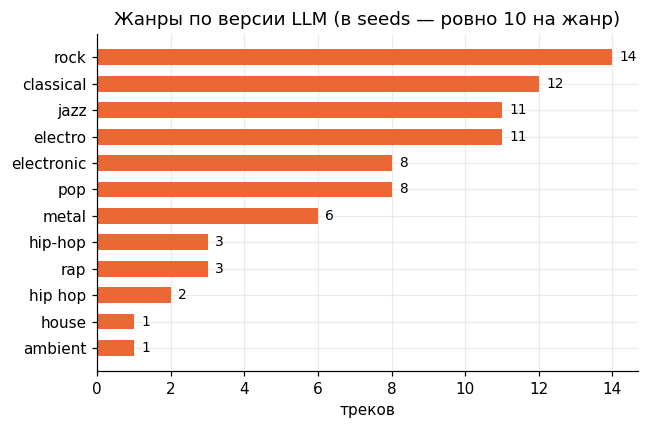

In [126]:
vc = df.llm_genre.value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(vc.index[::-1], vc.values[::-1], color=C_LLM, height=0.6)
for y, v in enumerate(vc.values[::-1]):
    ax.text(v + 0.2, y, v, va="center", fontsize=9)
ax.set_title("Жанры по версии LLM (в seeds — ровно 10 на жанр)")
ax.set_xlabel("треков")
fig.tight_layout(); fig.savefig(FIG / "genres_llm.png"); plt.show()

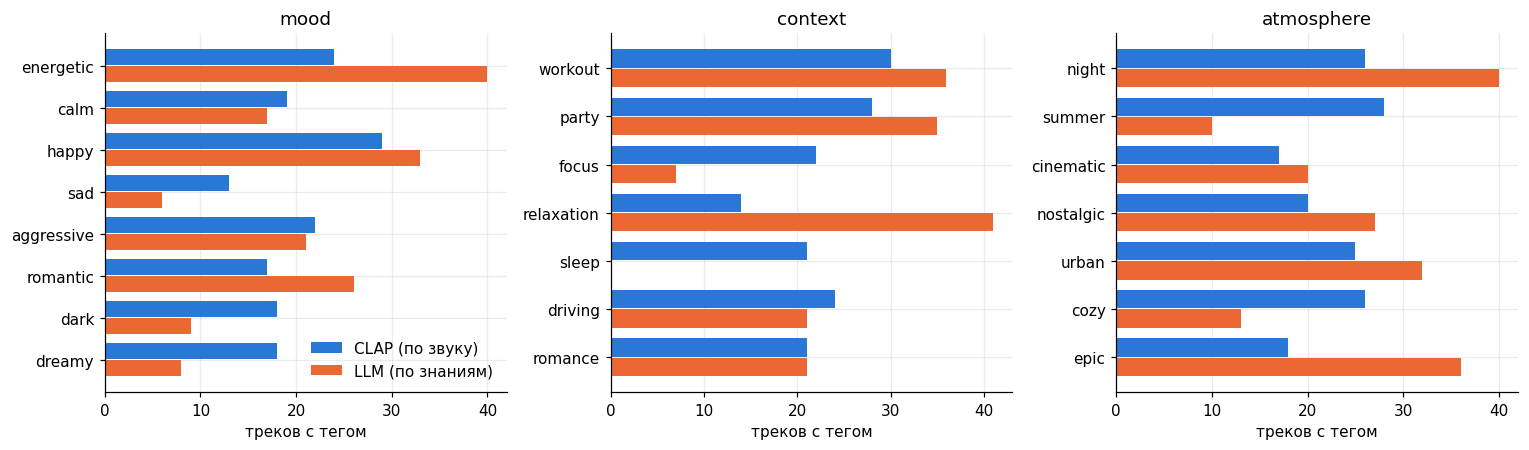

In [127]:
def tag_counts(col, labels):
    c = Counter(t for tags in df[col] for t in tags)
    return np.array([c[l] for l in labels])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, cat in zip(axes, ["mood", "context", "atmosphere"]):
    labels = VOCAB[cat]
    y = np.arange(len(labels))
    ax.barh(y - 0.2, tag_counts(f"clap_{cat}", labels), 0.38, color=C_CLAP, label="CLAP (по звуку)")
    ax.barh(y + 0.2, tag_counts(f"llm_{cat}", labels), 0.38, color=C_LLM, label="LLM (по знаниям)")
    ax.set_yticks(y, labels); ax.invert_yaxis()
    ax.set_title(cat); ax.set_xlabel("треков с тегом")
axes[0].legend(loc="lower right", frameon=False)
fig.tight_layout(); fig.savefig(FIG / "tags_clap_vs_llm.png"); plt.show()

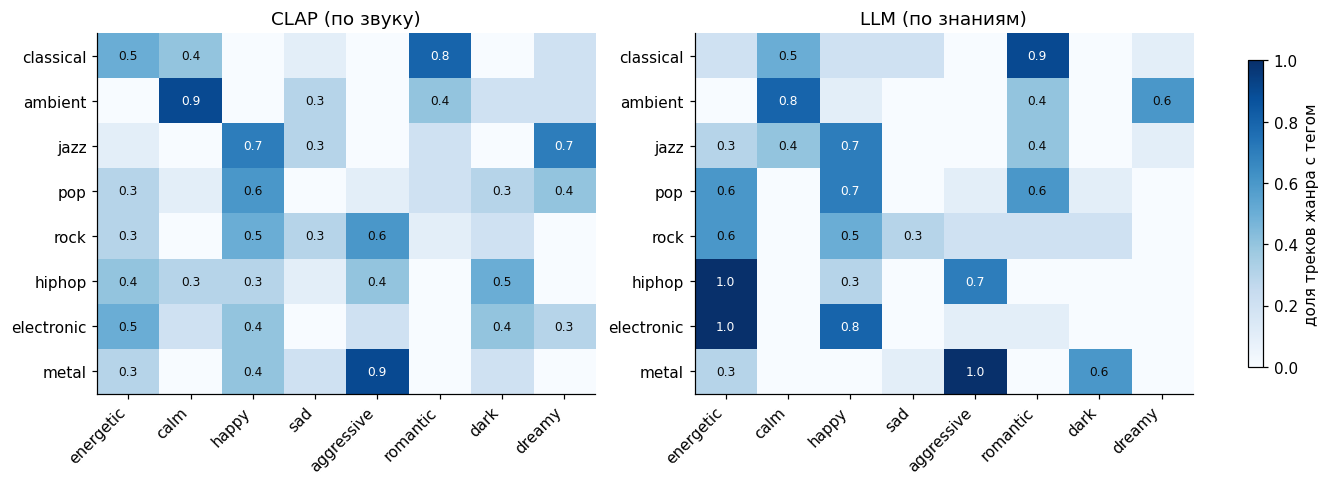

In [128]:
def genre_tag_share(col, labels):
    return pd.DataFrame({
        l: df.groupby("seed_genre")[col].apply(lambda s: np.mean([l in t for t in s]))
        for l in labels
    }).loc[GENRE_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
for ax, src, name in zip(axes, ["clap", "llm"], ["CLAP (по звуку)", "LLM (по знаниям)"]):
    M = genre_tag_share(f"{src}_mood", VOCAB["mood"])
    im = ax.imshow(M.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(M.shape[1]), M.columns, rotation=45, ha="right")
    ax.set_yticks(range(M.shape[0]), M.index)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            if v >= 0.3:                                   # подписываем только заметные значения
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                        color="white" if v > 0.6 else "#0b0b0b")
    ax.set_title(name); ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.85, label="доля треков жанра с тегом")
fig.savefig(FIG / "mood_by_genre.png"); plt.show()

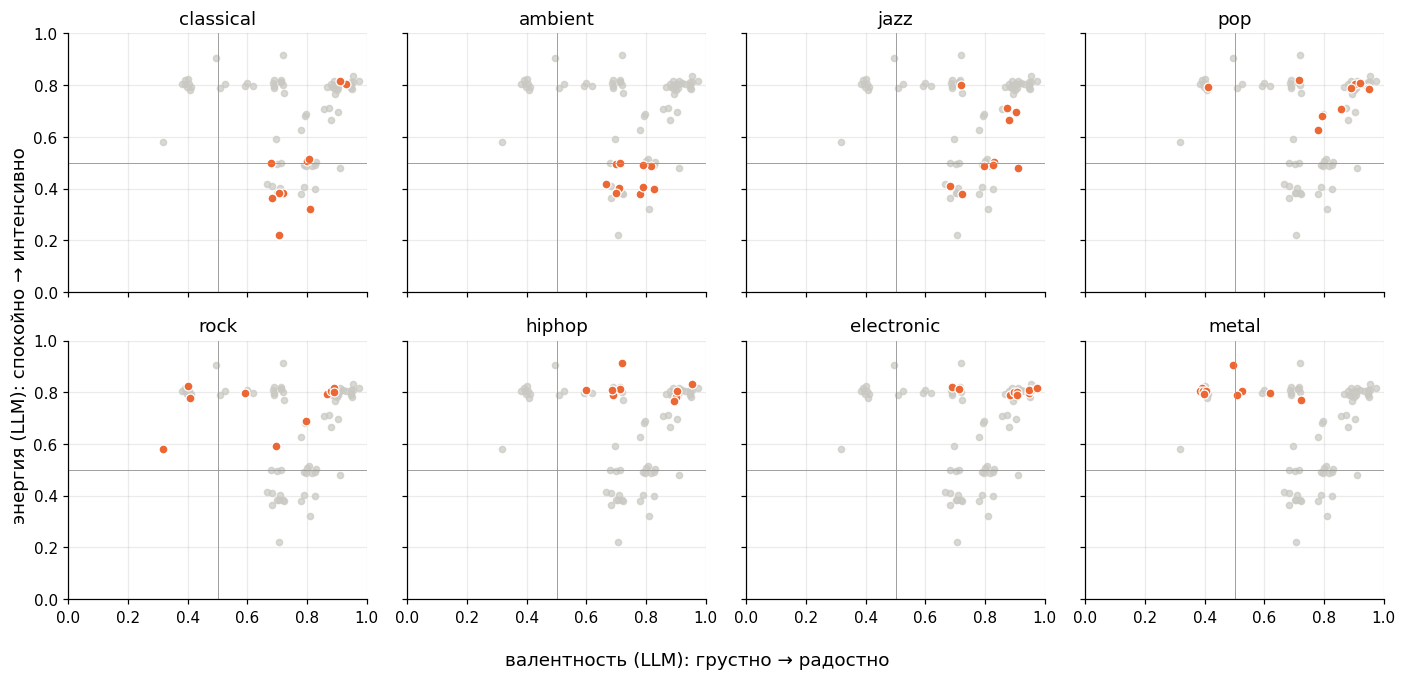

In [129]:
rng = np.random.default_rng(0)
jx = rng.normal(0, 0.015, len(df)); jy = rng.normal(0, 0.015, len(df))   # LLM ставит круглые числа — раздвигаем точки
x, y = df.llm_valence + jx, df.llm_energy + jy

fig, axes = plt.subplots(2, 4, figsize=(13, 6.2), sharex=True, sharey=True)
for ax, g in zip(axes.flat, GENRE_ORDER):
    mine = df.seed_genre == g
    ax.scatter(x[~mine], y[~mine], s=16, color=C_GRAY, alpha=0.7)
    ax.scatter(x[mine], y[mine], s=34, color=C_LLM, edgecolor="white", linewidth=0.8)
    ax.axhline(0.5, color="#999", lw=0.6); ax.axvline(0.5, color="#999", lw=0.6)
    ax.set_title(g); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
fig.supxlabel("валентность (LLM): грустно → радостно")
fig.supylabel("энергия (LLM): спокойно → интенсивно")
fig.tight_layout(); fig.savefig(FIG / "russell_map.png"); plt.show()

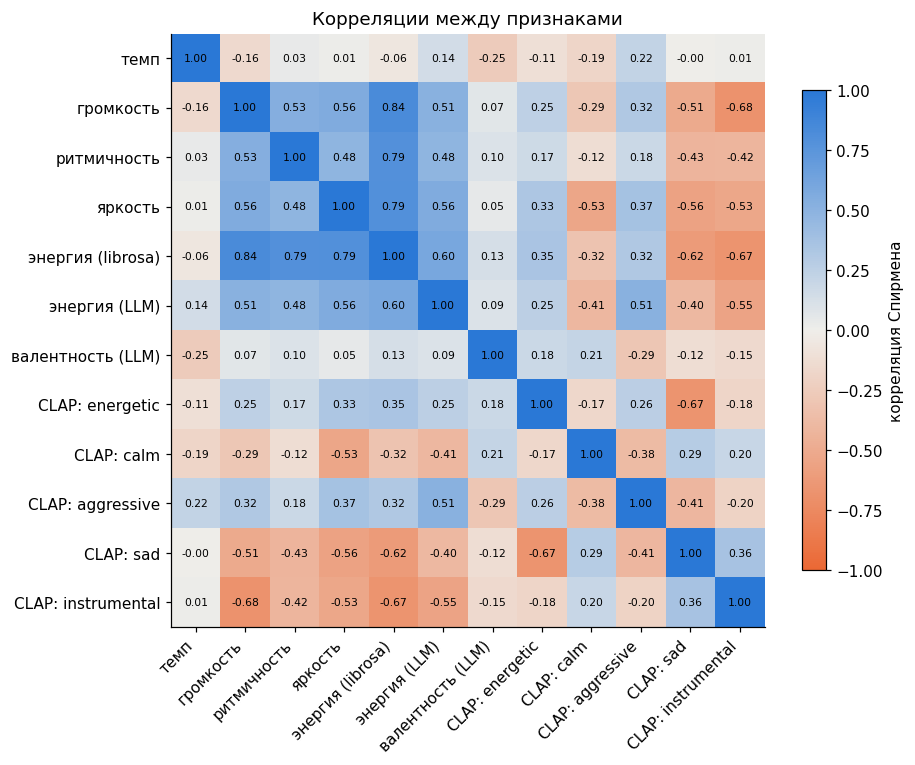

mood        согласие CLAP и LLM: 0.38  (случайный уровень 0.21)
context     согласие CLAP и LLM: 0.36  (случайный уровень 0.21)
atmosphere  согласие CLAP и LLM: 0.24  (случайный уровень 0.21)


In [130]:
cols = {
    "tempo": "темп", "rms": "громкость", "onset_strength": "ритмичность", "centroid": "яркость",
    "energy_audio": "энергия (librosa)", "llm_energy": "энергия (LLM)", "llm_valence": "валентность (LLM)",
    "clap_mood_energetic": "CLAP: energetic", "clap_mood_calm": "CLAP: calm",
    "clap_mood_aggressive": "CLAP: aggressive", "clap_mood_sad": "CLAP: sad",
    "clap_vocals_instrumental": "CLAP: instrumental",
}
Cm = df[list(cols)].rename(columns=cols).corr(method="spearman")
div = LinearSegmentedColormap.from_list("div", ["#eb6834", "#efeeea", "#2a78d6"])  # −1 оранжевый, 0 серый, +1 синий

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(Cm.values, cmap=div, vmin=-1, vmax=1)
ax.set_xticks(range(len(Cm)), Cm.columns, rotation=45, ha="right")
ax.set_yticks(range(len(Cm)), Cm.index)
for i in range(len(Cm)):
    for j in range(len(Cm)):
        ax.text(j, i, f"{Cm.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8, label="корреляция Спирмена")
ax.set_title("Корреляции между признаками")
fig.tight_layout(); fig.savefig(FIG / "correlations.png"); plt.show()

# Согласие CLAP и LLM по тегам — в сравнении со случайным уровнем
def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else np.nan

rng = np.random.default_rng(0)
for cat in ["mood", "context", "atmosphere"]:
    real = np.nanmean([jaccard(a, b) for a, b in zip(df[f"clap_{cat}"], df[f"llm_{cat}"])])
    chance = np.mean([np.nanmean([jaccard(a, b) for a, b in
                      zip(df[f"clap_{cat}"], rng.permutation(df[f"llm_{cat}"].values))])
                      for _ in range(200)])
    print(f"{cat:11s} согласие CLAP и LLM: {real:.2f}  (случайный уровень {chance:.2f})")

## Выводы по EDA

**Жанры.** В seeds жанры сбалансированы по построению (10 на жанр), поэтому смотрел,
как их называет LLM. Свободный текст дробит один жанр на варианты (hip-hop / rap / hip hop),
LLM злоупотребляет ярлыком «electro» и почти не использует «ambient» (1 трек из 10).
Вывод: жанр тоже стоит брать из закрытого словаря.

**Настроения и контексты.** У LLM сильный сдвиг в стереотипные теги: energetic, relaxation,
night и epic встречаются у 36–41 трека, а sleep — ни разу (LLM сливает его с relaxation).
У CLAP распределение ровнее, но это частично эффект центрирования, поэтому абсолютные
частоты тегов CLAP интерпретировать нельзя — только сравнение треков между собой.

**Теги осмысленны.** По профилю настроений жанров CLAP и LLM независимо сходятся в главном:
metal → aggressive, ambient → calm, classical → romantic, jazz → happy.

**Карта энергия × валентность.** Жанры разделяются по энергии, но у LLM сильное позитивное
смещение: почти все треки получили валентность выше 0,5, кроме metal. Кроме того, LLM
использует всего несколько уровней энергии (≈0,4 / 0,5 / 0,8), так что её числовые шкалы грубые.

**Корреляции.**
- Энергия LLM и librosa согласуются умеренно (Спирмен 0,60).
- CLAP «sad» сильно отрицательно связан с громкостью и энергией (−0,51 и −0,62): модель
  путает грусть с тишиной. Валентность по звуку ловится плохо.
- CLAP «instrumental» связан с низкой громкостью (−0,68): в датасете инструментальные треки
  в основном тихие (classical, ambient), и признаки смешиваются через состав выборки.
- Темп не связан ни с чем (|r| < 0,25) — для рекомендаций он малополезен.

**Согласие CLAP и LLM** (Жаккар против случайного уровня при перемешивании):
mood 0,38 против 0,21, context 0,36 против 0,21, atmosphere 0,24 против 0,21.
Настроение и контекст оба источника видят выше случайного, а атмосфера почти случайна —
это самый субъективный и наименее надёжный признак.

# Задание 5. Эксперименты с представлением треков.

In [131]:
!pip install -q umap-learn sentence-transformers "transformers<5"

In [132]:
from sentence_transformers import SentenceTransformer

emb_model = SentenceTransformer("intfloat/multilingual-e5-base", device="cuda")
texts = ("passage: " + df.llm_genre + ", " + df.llm_subgenre + ". " + df.llm_description).tolist()
E_txt = emb_model.encode(texts, normalize_embeddings=True)
print(E_txt.shape)

(80, 768)


In [133]:
from sklearn.preprocessing import StandardScaler, normalize

def l2(X):
    return normalize(np.asarray(X, dtype=float))

def center_l2(X):
    X = np.asarray(X, dtype=float)
    return l2(X - X.mean(0))        # убираем общее для всех треков направление

def multi_hot(col, labels):
    return np.array([[l in tags for l in labels] for tags in df[col]], dtype=float)

lib = StandardScaler().fit_transform(df[["tempo", "rms", "onset_strength", "centroid"]])
clap_soft = StandardScaler().fit_transform(df.filter(regex=r"^clap_(mood|context|atmosphere|vocals)_"))
llm_tags = np.hstack(
    [multi_hot(f"llm_{c}", VOCAB[c]) for c in ["mood", "context", "atmosphere"]]
    + [(df.llm_vocals == "instrumental").values[:, None].astype(float),
       df[["llm_energy", "llm_valence"]].fillna(0.5).values]
)

REPS = {
    "librosa": l2(lib),
    "CLAP теги": l2(clap_soft),
    "LLM теги": center_l2(llm_tags),
    "CLAP аудио": center_l2(A),
    "LLM текст": center_l2(E_txt),
}
REPS["CLAP аудио + LLM текст"] = l2(np.hstack([REPS["CLAP аудио"], REPS["LLM текст"]]))
{k: v.shape for k, v in REPS.items()}

{'librosa': (80, 4),
 'CLAP теги': (80, 24),
 'LLM теги': (80, 25),
 'CLAP аудио': (80, 512),
 'LLM текст': (80, 768),
 'CLAP аудио + LLM текст': (80, 1280)}

In [134]:
artist_norm = df.artist.map(norm).values
related = [set(map(norm, r)) for r in df.related_artists]
# треки, у которых хотя бы один «похожий» по Deezer артист есть в нашем датасете
has_rel = np.array([any(a in rel for a in artist_norm) for rel in related])

def neighbors(X, k):
    S = X @ X.T
    np.fill_diagonal(S, -np.inf)                       # сам трек — не сосед
    return np.argsort(-S, axis=1)[:, :k]

def evaluate(X):
    nn5 = neighbors(X, 5)
    genre_p = (df.seed_genre.values[nn5] == df.seed_genre.values[:, None]).mean()
    nn10 = neighbors(X, 10)
    rel_hit = np.mean([any(artist_norm[j] in related[i] for j in nn10[i]) for i in np.where(has_rel)[0]])
    return genre_p, rel_hit

rng = np.random.default_rng(0)
rand = np.mean([evaluate(l2(rng.normal(size=(len(df), 64)))) for _ in range(50)], axis=0)

res = pd.DataFrame({name: evaluate(X) for name, X in REPS.items()},
                   index=["жанр P@5", "похожий артист в топ-10"]).T
res.loc["случайные векторы"] = rand
print("треков, для которых есть эталон «похожий артист»:", has_rel.sum(), "из", len(df))
res.round(2).sort_values("жанр P@5")

треков, для которых есть эталон «похожий артист»: 57 из 80


,жанр P@5,похожий артист в топ-10
случайные векторы,0.11,0.17
librosa,0.26,0.42
LLM теги,0.42,0.65
CLAP теги,0.48,0.63
CLAP аудио,0.57,0.79
LLM текст,0.66,0.75
CLAP аудио + LLM текст,0.71,0.86


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


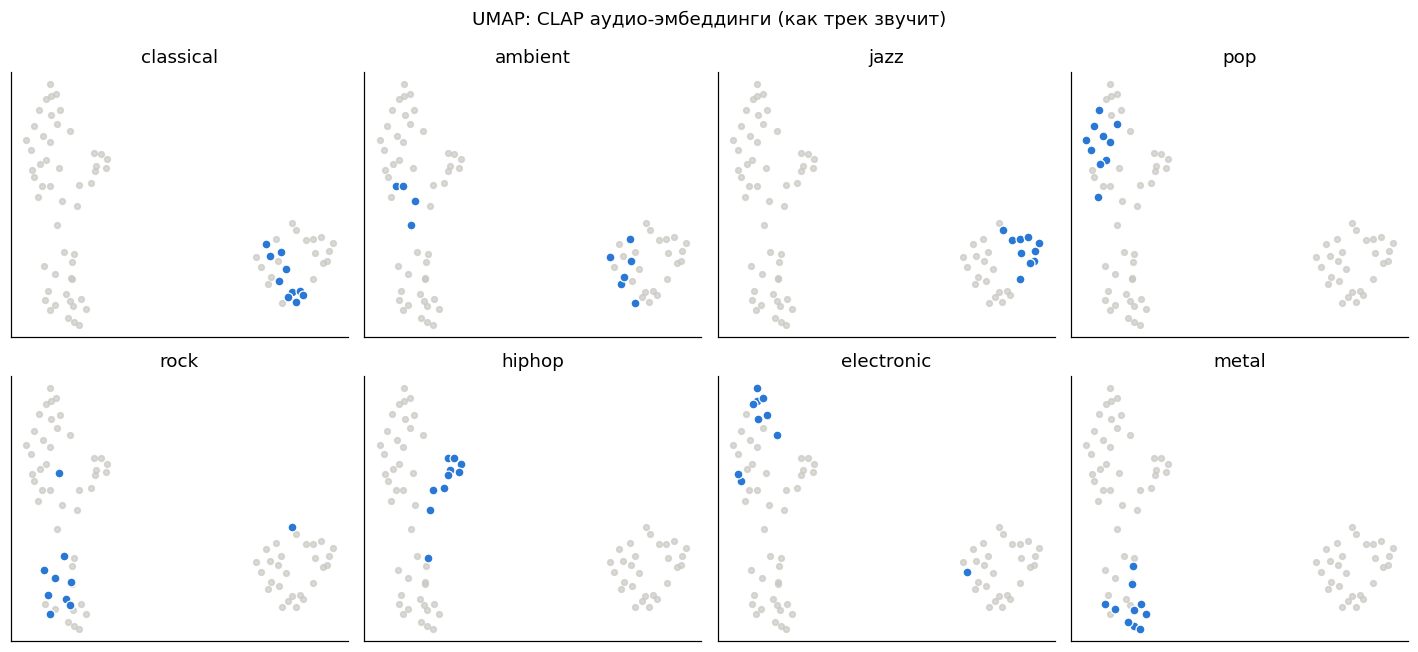

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


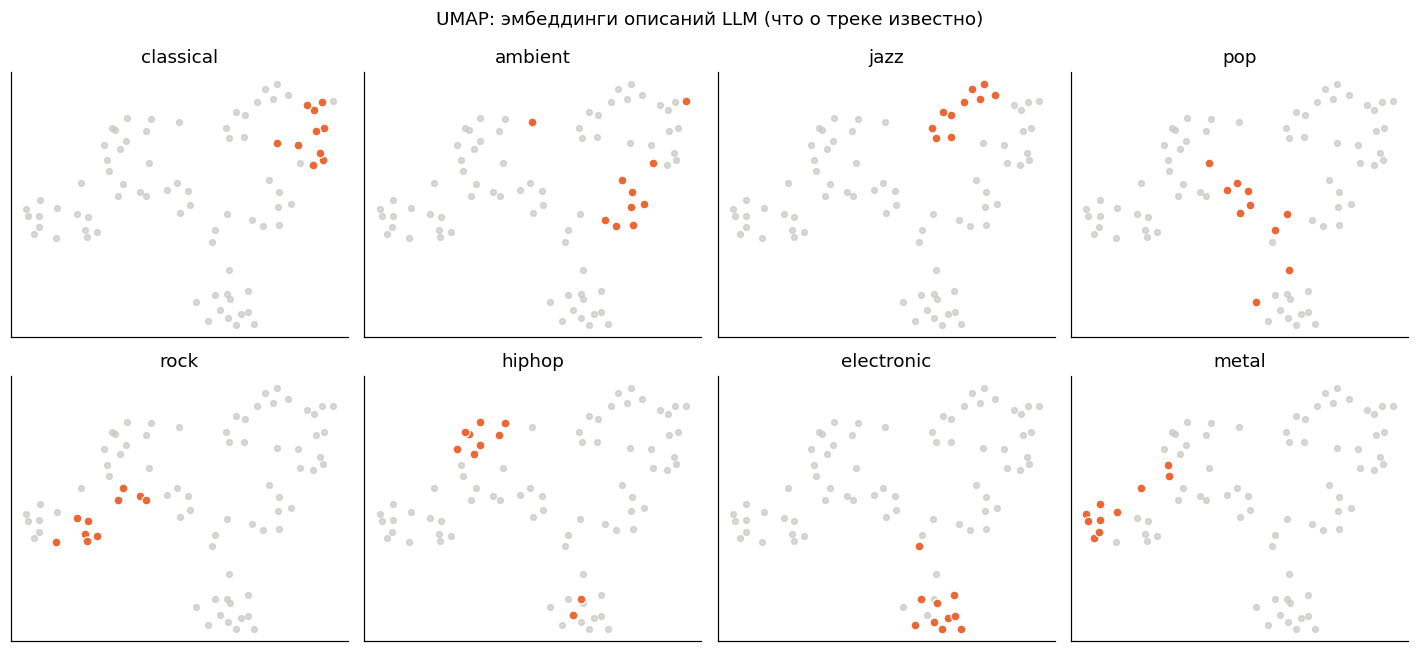

In [135]:
import umap

def umap_grid(X, title, color, fname):
    Z = umap.UMAP(n_neighbors=10, min_dist=0.3, metric="cosine", random_state=42).fit_transform(X)
    fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True, sharey=True)
    for ax, g in zip(axes.flat, GENRE_ORDER):
        mine = (df.seed_genre == g).values
        ax.scatter(Z[~mine, 0], Z[~mine, 1], s=14, color=C_GRAY, alpha=0.7)
        ax.scatter(Z[mine, 0], Z[mine, 1], s=34, color=color, edgecolor="white", linewidth=0.8)
        ax.set_title(g); ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(title); fig.tight_layout(); fig.savefig(FIG / fname); plt.show()

umap_grid(REPS["CLAP аудио"], "UMAP: CLAP аудио-эмбеддинги (как трек звучит)", C_CLAP, "umap_clap.png")
umap_grid(REPS["LLM текст"], "UMAP: эмбеддинги описаний LLM (что о треке известно)", C_LLM, "umap_llm.png")

In [136]:
def show_neighbors(i, reps=("CLAP аудио", "LLM текст", "CLAP аудио + LLM текст"), k=3):
    rows = []
    for name in reps:
        X = REPS[name]
        s = X @ X[i]; s[i] = -np.inf
        for r, j in enumerate(np.argsort(-s)[:k], 1):
            rows.append({"представление": name, "#": r,
                         "сосед": f"{df.artist.iloc[j]} — {df.title.iloc[j]}",
                         "жанр": df.seed_genre.iloc[j], "сходство": round(float(s[j]), 2)})
    print(f"\nЗапрос: {df.artist.iloc[i]} — {df.title.iloc[i]} ({df.seed_genre.iloc[i]})")
    display(pd.DataFrame(rows))

for a in ["Daft Punk", "Claude Debussy", "Кино", "Rammstein", "Nujabes", "Ludovico Einaudi"]:
    show_neighbors(int(np.where(df.artist == a)[0][0]))


Запрос: Daft Punk — One More Time (electronic)


,представление,#,сосед,жанр,сходство
0,CLAP аудио,1,Avicii — Levels,electronic,0.61
1,CLAP аудио,2,Swedish House Mafia — Don't You Worry Child,electronic,0.58
2,CLAP аудио,3,Calvin Harris — Summer,electronic,0.55
3,LLM текст,1,Скриптонит — Положение,hiphop,0.46
4,LLM текст,2,Calvin Harris — Summer,electronic,0.43
5,LLM текст,3,Avicii — Levels,electronic,0.36
6,CLAP аудио + LLM текст,1,Calvin Harris — Summer,electronic,0.49
7,CLAP аудио + LLM текст,2,Avicii — Levels,electronic,0.48
8,CLAP аудио + LLM текст,3,Swedish House Mafia — Don't You Worry Child,electronic,0.39



Запрос: Claude Debussy — Clair de Lune (classical)


,представление,#,сосед,жанр,сходство
0,CLAP аудио,1,Erik Satie — Gymnopédie No. 1,classical,0.87
1,CLAP аудио,2,Ludwig van Beethoven — Für Elise,classical,0.73
2,CLAP аудио,3,Aphex Twin — Avril 14th,ambient,0.56
3,LLM текст,1,Ludovico Einaudi — Nuvole Bianche,ambient,0.37
4,LLM текст,2,Ludwig van Beethoven — Für Elise,classical,0.37
5,LLM текст,3,Wolfgang Amadeus Mozart — Eine kleine Nachtmusik,classical,0.33
6,CLAP аудио + LLM текст,1,Erik Satie — Gymnopédie No. 1,classical,0.57
7,CLAP аудио + LLM текст,2,Ludwig van Beethoven — Für Elise,classical,0.55
8,CLAP аудио + LLM текст,3,Ludovico Einaudi — Nuvole Bianche,ambient,0.37



Запрос: Кино — Группа крови (rock)


...

,представление,#,сосед,жанр,сходство
0,CLAP аудио,1,Sabaton — Primo Victoria,metal,0.52
1,CLAP аудио,2,Metallica — Enter Sandman,metal,0.50
2,CLAP аудио,3,Би-2 — Полковнику никто не пишет,rock,0.48
3,LLM текст,1,Slipknot — Duality,metal,0.24
4,LLM текст,2,Black Sabbath — Paranoid,metal,0.22
5,LLM текст,3,Megadeth — Symphony Of Destruction,metal,0.22
6,CLAP аудио + LLM текст,1,Metallica — Enter Sandman,metal,0.35
7,CLAP аудио + LLM текст,2,Slipknot — Duality,metal,0.31
8,CLAP аудио + LLM текст,3,Megadeth — Symphony Of Destruction,metal,0.31



Запрос: Nujabes — Aruarian Dance (ambient)


,представление,#,сосед,жанр,сходство
0,CLAP аудио,1,Bonobo — Kerala,ambient,0.34
1,CLAP аудио,2,Moby — Porcelain,ambient,0.31
2,CLAP аудио,3,Скриптонит — Положение,hiphop,0.30
3,LLM текст,1,Dr. Dre — Still D.R.E.,hiphop,0.12
4,LLM текст,2,Herbie Hancock — Cantaloupe Island,jazz,0.12
5,LLM текст,3,Баста — Сансара,hiphop,0.12
6,CLAP аудио + LLM текст,1,Bonobo — Kerala,ambient,0.19
7,CLAP аудио + LLM текст,2,Dr. Dre — Still D.R.E.,hiphop,0.19
8,CLAP аудио + LLM текст,3,The Dave Brubeck Quartet — Take Five,jazz,0.18



Запрос: Ludovico Einaudi — Nuvole Bianche (ambient)


,представление,#,сосед,жанр,сходство
0,CLAP аудио,1,Sergei Rachmaninoff — Piano Concerto No. 2,classical,0.64
1,CLAP аудио,2,Edvard Grieg — In the Hall of the Mountain King,classical,0.63
2,CLAP аудио,3,Erik Satie — Gymnopédie No. 1,classical,0.57
3,LLM текст,1,Erik Satie — Gymnopédie No. 1,classical,0.43
4,LLM текст,2,Wolfgang Amadeus Mozart — Eine kleine Nachtmusik,classical,0.38
5,LLM текст,3,Claude Debussy — Clair de Lune,classical,0.37
6,CLAP аудио + LLM текст,1,Erik Satie — Gymnopédie No. 1,classical,0.50
7,CLAP аудио + LLM текст,2,Wolfgang Amadeus Mozart — Eine kleine Nachtmusik,classical,0.43
8,CLAP аудио + LLM текст,3,Sergei Rachmaninoff — Piano Concerto No. 2,classical,0.39


In [137]:
queries = ["calm piano music for sleep", "energetic music for a workout",
           "sad melancholic song", "music for a night drive", "happy upbeat party music"]
S = A @ clap_text_emb(queries).T        # нецентрированные A: здесь нужно общее пространство с текстом
for qi, q in enumerate(queries):
    print(f"\n«{q}»")
    for j in np.argsort(-S[:, qi])[:5]:
        print(f"   {df.artist.iloc[j]} — {df.title.iloc[j]} ({df.seed_genre.iloc[j]})")


«calm piano music for sleep»
   Erik Satie — Gymnopédie No. 1 (classical)
   Sergei Rachmaninoff — Piano Concerto No. 2 (classical)
   Aphex Twin — Avril 14th (ambient)
   Ludovico Einaudi — Nuvole Bianche (ambient)
   Claude Debussy — Clair de Lune (classical)

«energetic music for a workout»
   Wolfgang Amadeus Mozart — Eine kleine Nachtmusik (classical)
   Avicii — Levels (electronic)
   Little Big — Skibidi (electronic)
   Tycho — Awake (ambient)
   Pyotr Ilyich Tchaikovsky — Swan Lake (classical)

«sad melancholic song»
   Erik Satie — Gymnopédie No. 1 (classical)
   Sergei Rachmaninoff — Piano Concerto No. 2 (classical)
   Aphex Twin — Avril 14th (ambient)
   Queen — Bohemian Rhapsody (rock)
   Claude Debussy — Clair de Lune (classical)

«music for a night drive»
   The Chemical Brothers — Galvanize (electronic)
   Zivert — Life (pop)
   The Weeknd — Blinding Lights (pop)
   Tycho — Awake (ambient)
   Little Big — Skibidi (electronic)

«happy upbeat party music»
   The Chemical 

## Выводы по заданию 5

### Модель похожести

Косинусное сходство векторов + k ближайших соседей. Отдельную модель не обучал:
на 80 треках ей не на чем учиться, а вопрос задания — про качество самих признаков.
Похожесть оценивал по двум эталонам, которых нет среди признаков:
- **жанр P@5** — доля соседей того же жанра (по seeds) среди 5 ближайших;
- **похожий артист в топ-10** — есть ли среди 10 соседей артист из списка «похожих» Deezer
  (считается для 57 из 80 треков, у которых такой артист вообще есть в датасете).

| Представление | Жанр P@5 | Похожий артист в топ-10 |
|---|---|---|
| случайные векторы | 0,11 | 0,17 |
| librosa | 0,26 | 0,42 |
| LLM теги | 0,42 | 0,65 |
| CLAP теги | 0,48 | 0,63 |
| CLAP аудио | 0,57 | 0,79 |
| LLM текст | 0,66 | 0,75 |
| CLAP аудио + LLM текст | **0,71** | **0,86** |

### Насколько признаки отражают реальную похожесть

- Все представления лучше случайного, но librosa (4 числа о сигнале) почти бесполезна.
- **Эмбеддинги лучше тегов** (CLAP 0,57 против 0,48, LLM 0,66 против 0,42): при сжатии
  до словаря теряется информация. Теги полезны для фильтров и объяснимости, эмбеддинги — для похожести.
- **Лучший результат — комбинация звука и знаний** по обеим метрикам: источники дополняют
  друг друга. Звук лучше по независимому эталону (похожие артисты), знания — по жанру
  (но в тексте LLM прямо написан жанр, так что эта метрика ему подыгрывает).
- Звук и знания находят **разные виды похожести**. CLAP ставит рядом с Кино Beatles и Rammstein
  (похоже звучат), LLM — Сплин и Би-2 (одна культура и язык). Для Debussy CLAP находит
  Aphex Twin «Avril 14th» — по жанру это ошибка, а на слух очень похоже (сольное фортепиано).
  Метрика по жанру занижает реальную похожесть.
- **Ошибки разметки переходят в похожесть**: LLM назвала русский хип-хоп «electro/house»,
  и ближайшим соседом Daft Punk в LLM-представлении стал Скриптонит. Комбинация с аудио это исправляет.

### UMAP

По звуку пространство делится на «акустическое» (classical, jazz, часть ambient) и
«спродюсированное» (pop, electronic, hiphop, rock, metal), а rock и metal сливаются.
По знаниям жанры разделены чётче, но русский хип-хоп попадает в кластер electronic.

### Бонус: поиск треков по текстовому запросу через CLAP

Запросы с акустическим смыслом работают хорошо («calm piano music for sleep» → Satie,
Rachmaninoff, Debussy). Запросы с культурным смыслом — плохо: на «energetic music for a workout»
первым идёт Моцарт. «Sad» и «calm» дают почти одну выдачу: CLAP путает грусть с тишиной.

### Какие признаки оказались наиболее полезными

1. Аудио-эмбеддинг CLAP и текстовый эмбеддинг LLM-описания, особенно вместе.
2. Вокал / инструментал (точность 0,80–0,90) и энергия (согласуется в трёх источниках).
3. Жанр от LLM (0,90), но с нормализацией и осторожностью на русских треках.

Наименее полезные: темп (ни с чем не связан), валентность (позитивное смещение LLM,
CLAP путает с тишиной) и атмосфера (согласие CLAP и LLM на уровне случайного).

# Выводы

## Что это значит для музыкальных рекомендаций

1. **Звук и знания дополняют друг друга.** CLAP знает, как трек звучит, LLM — что о нём
   известно. Их комбинация — лучшее представление по обоим эталонам
   (жанр P@5 0,71, похожий артист в топ-10 0,86 против 0,11 / 0,17 у случайного).
2. **Эмбеддинги — для похожести, теги — для фильтров и объяснений.** При сжатии трека
   до словаря из 24 тегов похожесть падает, но теги нужны там, где пользователь
   задаёт явное условие: «только инструментальное», «поновее», «спокойное».
3. **Надёжность признаков разная.**
   - надёжны: вокал / инструментал (0,79–0,90 по эталону), энергия (согласуется
     в трёх источниках), жанр от LLM (0,90);
   - ненадёжны: валентность (у LLM позитивное смещение, CLAP путает грусть с тишиной),
     атмосфера (согласие CLAP и LLM на уровне случайного), темп (ни с чем не связан);
   - эпоха: ни один источник не надёжен (Deezer даёт даты ремастеров, LLM ошибается
     на граничных годах).
4. **CLAP уже работает как zero-shot поиск по акустическим интентам**
   («calm piano music for sleep» → Satie, Rachmaninoff, Debussy), но не по культурным
   («energetic music for a workout» → Моцарт первым). Для культурных интентов нужны знания.
5. **LLM хуже знает русскоязычную музыку и не знает, чего не знает:** ошибки в жанре
   и эпохе сосредоточены на русских треках, а самооценка уверенности почти всегда «high».
   Для русскоязычного каталога это главный риск LLM-разметки.

**Вывод для прототипа:** CLAP-поиск по тексту запроса даёт кандидатов, теги и описание
от LLM служат для фильтров и переранжирования. Признаки, которые проверяются по эталону
(вокал, жанр, энергия), можно использовать сразу, а валентность и атмосферу — только
после ручной разметки части данных для проверки.

## Ограничения и проблемы

- **Маленькая выборка:** 80 треков, отобранных одним человеком. Жанровые ярлыки seeds
  местами спорны (Einaudi, Nujabes), а эти ярлыки — один из эталонов.
- **Эталоны косвенные:** жанр и «похожие артисты» Deezer — не то же самое, что похожесть
  в восприятии пользователя. Эталон «похожий артист» есть только для 57 из 80 треков.
- **Часть решений принята на тех же данных, на которых оценивалась**
  (центрирование тегов, выбор чекпоинта CLAP), поэтому оценки немного оптимистичны.
- **Каталог Deezer зависит от региона сервера**, поэтому датасет при пересборке
  меняется. Собранный датасет зафиксирован в `data/tracks_meta.jsonl`.
- **30-секундные превью** не передают трек целиком, особенно в классике и ambient.
- **Теги CLAP относительные** после центрирования: «calm» значит «спокойнее среднего
  в этом датасете».
- **Технические проблемы:** чекпоинт `laion/larger_clap_music` даёт вырожденные
  эмбеддинги; нужно `transformers<5` и bitsandbytes для 4-битной Qwen.

